# ClueX
**Machine Learning Unit 4 & 5 — final project** · Lamyaa Alnahdi · Raghad Alqahtani · Rawan Alsubaie

| Step | Section |
|---|---|
| 1. Problem definition | §1 |
| 2. Exploratory data analysis | §2–3 |
| 3. Preprocessing | §4 |
| 4. Modeling | §5 |
| 5. Evaluation | §6–7 |
| 6. Model selection | §8 |
| 7. Deployment | §9 (the live app) |

## 1 · Problem
State-backed influence operations flood chosen tweets with replies from accounts that work together.
To a reader it looks like public opinion.

**Goal:** given how an account replied (timing, text similarity, profile, who it replied with), predict whether
it belongs to an operation. **Target:** `replier_label` — 1 = removed by Twitter as part of an operation, 0 = normal.

**Data:** OSoMe *Coordinated Reply Attacks* (Indiana University, ICWSM 2025), Zenodo 10.5281/zenodo.13896308, CC BY 4.0.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from radar import config as C, model as M
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.3f}".format)

NORMAL, IO = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True, "legend.frameon": False,
                     "axes.titleweight": "bold"})
NAMES = {"logreg": "Logistic Regression", "rf": "Random Forest", "hgb": "Gradient Boosting"}

## 2 · The data

In [2]:
df = pd.read_pickle(ROOT / "artifacts" / "accounts.pkl")   # one row per account (built by radar.pipeline)
features = [c for c in pd.read_json(ROOT / "artifacts" / "run_info.json", typ="series")["feature_columns"]]
print(f"{len(df):,} accounts × {len(features)} features")
df[[C.COL_USER, "campaign_group", "age", "mean_diff_min", "mean_cosine", "followers_ratio", C.COL_LABEL]].head()

794,645 accounts × 76 features


,replier_userid,campaign_group,age,mean_diff_min,mean_cosine,followers_ratio,replier_label
0,1000000209278021632,other,0.057,6.000,0.071,5.125,0
1,1000000283106250754,sa_eg_ae_022020,1.333,1.000,0.000,171.436,0
2,1000001637711335425,other,0.008,2.000,0.176,1.000,0
3,1000001923234369536,saudi_arabia_112019,0.025,13.000,0.000,23.580,0
4,1000002261119045632,saudi_arabia_112019,0.027,30.667,0.000,1.217,0


In [3]:
quality = pd.Series({"duplicate accounts": df[C.COL_USER].duplicated().sum(),
                     "missing values": int(df[features].isna().sum().sum()),
                     "infinite values": int(np.isinf(df[features]).sum().sum())})
quality.to_frame("count")

,count
duplicate accounts,0
missing values,0
infinite values,0


> **Takeaway:** one row per account, 76 numeric features, no duplicates, no missing or infinite values — the released data is clean, so preprocessing is mostly about the split and the class imbalance.

## 3 · Exploratory data analysis

### 3.1 How many operation accounts?

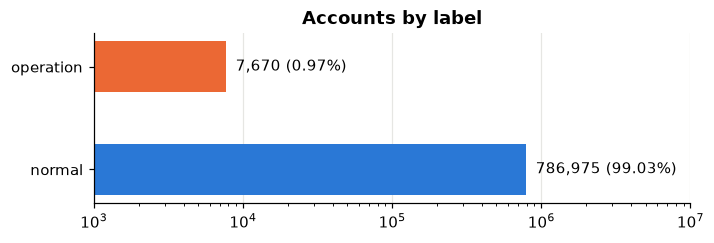

In [4]:
counts = df[C.COL_LABEL].value_counts().rename({0: "normal", 1: "operation"})
fig, ax = plt.subplots(figsize=(7, 2))
ax.barh(counts.index, counts.values, color=[NORMAL, IO], height=.5)
for i, n in enumerate(counts.values):
    ax.text(n, i, f"  {n:,} ({n / counts.sum():.2%})", va="center")
ax.set_xscale("log"); ax.set_xlim(1e3, 1e7); ax.grid(axis="y", visible=False); ax.set_title("Accounts by label")
plt.show()

> **Takeaway:** only **7,670 of 794,645 accounts (0.97 %)** are operation accounts. A model that always says “normal” is 99 % accurate and finds nothing — so accuracy alone cannot judge our models (see §6).

### 3.2 How operation accounts differ

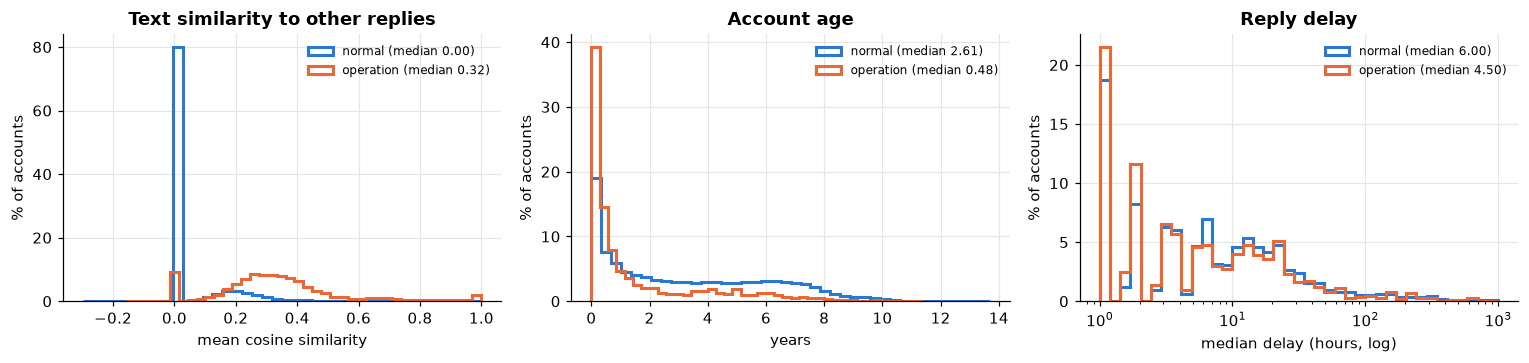

In [5]:
def compare(ax, col, title, bins, log=False, xlabel=""):
    for lab, name, c in [(0, "normal", NORMAL), (1, "operation", IO)]:
        x = df.loc[df[C.COL_LABEL] == lab, col].dropna()
        ax.hist(x, bins=bins, weights=np.full(len(x), 100 / len(x)), histtype="step", lw=2, color=c,
                label=f"{name} (median {x.median():.2f})")
    if log: ax.set_xscale("log")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("% of accounts"); ax.legend(fontsize=8)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
compare(ax[0], "mean_cosine", "Text similarity to other replies", 40, xlabel="mean cosine similarity")
compare(ax[1], "age", "Account age", 40, xlabel="years")
compare(ax[2], "50%_diff_min", "Reply delay", np.logspace(0, 3, 40), log=True, xlabel="median delay (hours, log)")
plt.tight_layout(); plt.show()

> **Takeaway:** operation accounts **copy each other** (text similarity 0.32 vs 0.00 — the clearest difference) and are **new** (median age 0.5 vs 2.6 years). Reply delay differs only a little (4.5 vs 6 hours).

### 3.3 Do they reply in groups?

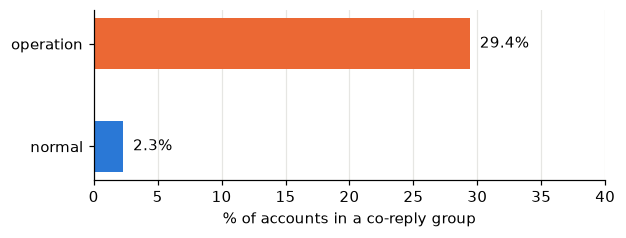

In [6]:
grp = (df.assign(in_group=df["graph_degree"].fillna(0) > 0)
         .groupby(C.COL_LABEL)["in_group"].mean().rename({0: "normal", 1: "operation"}) * 100)
fig, ax = plt.subplots(figsize=(6, 2))
ax.barh(grp.index, grp.values, color=[NORMAL, IO], height=.5)
for i, v in enumerate(grp.values): ax.text(v, i, f"  {v:.1f}%", va="center")
ax.set_xlabel("% of accounts in a co-reply group"); ax.grid(axis="y", visible=False); ax.set_xlim(0, 40)
plt.show()

> **Takeaway:** operation accounts are about **13× more likely** to sit in a co-reply group — accounts that keep replying to the same tweets together.

### 3.4 Is every campaign the same?

In [7]:
camp = (df.groupby("campaign_group").agg(accounts=(C.COL_LABEL, "size"), operation=(C.COL_LABEL, "sum"))
          .assign(share_pct=lambda d: d.operation / d.accounts * 100))
camp["median delay of operation accounts (h)"] = (df[df[C.COL_LABEL] == 1].groupby("campaign_group")["50%_diff_min"].median())
camp.sort_values("accounts", ascending=False)

,accounts,operation,share_pct,median delay of operation accounts (h)
campaign_group,,,,
saudi_arabia_112019,482243,1454,0.302,4.000
turkey_052020,145585,999,0.686,4.000
sa_eg_ae_022020,76808,735,0.957,13.500
other,70738,2455,3.471,10.000
serbia_022020,13011,1152,8.854,4.000
honduras_022020,6260,875,13.978,1.000


> **Takeaway:** campaigns are very different: the share of operation accounts goes from **0.3 %** (Saudi Arabia) to **14 %** (Honduras), and their reply delay from **1 hour** to **13.5 hours**. This is why §7 also tests on campaigns the model never saw.

## 4 · Preprocessing
| Step | Why |
|---|---|
| Keep only the 76 numeric behaviour features; drop IDs and the label | IDs would leak the answer |
| Replace ±∞ with missing | uploaded files can contain them; trees handle missing values |
| Split **before** any sampling (stratified, 80 % train / 20 % test) | the test set keeps the real 1 % share |
| Training set only: keep all operation accounts + 10 normal per operation account | 99 % normal would teach the model to say "normal" |
| Logistic Regression only: median imputation + scaling inside a pipeline | a linear model needs comparable scales |

In [8]:
X = df[features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
y = df[C.COL_LABEL].to_numpy()
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rng = np.random.default_rng(42)
keep = M.downsample(np.arange(len(y_tr)), y_tr, 10, rng)
X_bal, y_bal = X_tr[keep], y_tr[keep]
pd.DataFrame({"rows": [len(y_tr), len(y_bal), len(y_te)],
              "operation accounts": [y_tr.sum(), y_bal.sum(), y_te.sum()],
              "operation share": [y_tr.mean(), y_bal.mean(), y_te.mean()]},
             index=["train (all)", "train (after downsampling)", "test (untouched)"])

,rows,operation accounts,operation share
train (all),635716,6136,0.010
train (after downsampling),67496,6136,0.091
test (untouched),158929,1534,0.010


## 5 · Models
| Model | Why we tried it |
|---|---|
| Logistic Regression | simple, interpretable baseline |
| Random Forest | the model used in the original research paper |
| Gradient Boosting (HistGradientBoosting) | usually strongest on tabular data; fast; handles missing values |

Each model also learns a **decision threshold** on a validation part of the training data (the cut-off that gives
the best F1), because the training data is 10:1 while real data is about 100:1.

In [9]:
fitted = {}
for name in ["logreg", "rf", "hgb"]:
    fitted[name] = M.fit_with_threshold(name, X_bal, y_bal)      # (model, threshold)
    print(f"{NAMES[name]:<20} threshold = {fitted[name][1]:.2f}")

Logistic Regression  threshold = 0.75


Random Forest        threshold = 0.36


Gradient Boosting    threshold = 0.45


## 6 · Evaluation on the test set (accuracy · precision · recall · F1)

In [10]:
def scores(y_true, p, thr):
    pred = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred), "pr_auc": average_precision_score(y_true, p)}

rows = {"Always 'normal' (baseline)": scores(y_te, np.zeros(len(y_te)), .5)}
probs = {}
for name, (m, thr) in fitted.items():
    probs[name] = m.predict_proba(X_te)[:, 1]
    rows[NAMES[name]] = scores(y_te, probs[name], thr)
test_table = pd.DataFrame(rows).T
test_table

,accuracy,precision,recall,f1,pr_auc
Always 'normal' (baseline),0.990,0.000,0.000,0.000,0.010
Logistic Regression,0.956,0.153,0.776,0.255,0.258
Random Forest,0.983,0.343,0.851,0.488,0.725
Gradient Boosting,0.988,0.446,0.829,0.580,0.767


> **Takeaway:**
> - The “always normal” baseline has **99 % accuracy but 0 F1** — accuracy is misleading here, so we compare models on **precision, recall and F1**.
> - **Gradient Boosting is best:** F1 **0.58**, precision 0.45, recall 0.83. Random Forest: F1 0.49. Logistic Regression: F1 0.26.
> - PR-AUC (last column) measures how well each model puts operation accounts at the top of its ranked list: 1 = perfect, random = 0.01.

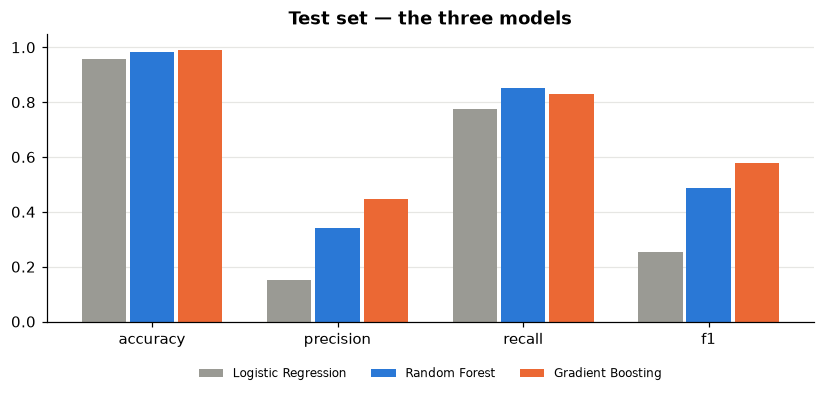

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.4))
show = test_table.drop(index="Always 'normal' (baseline)")[["accuracy", "precision", "recall", "f1"]]
xs = np.arange(len(show.columns)); w = .26
for i, (name, row) in enumerate(show.iterrows()):
    ax.bar(xs + (i - 1) * w, row.values, w * .92, label=name, color=["#9a9a94", NORMAL, IO][i])
ax.set_xticks(xs, show.columns); ax.set_ylim(0, 1.05); ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12))
ax.set_title("Test set — the three models"); ax.grid(axis="x", visible=False)
plt.show()

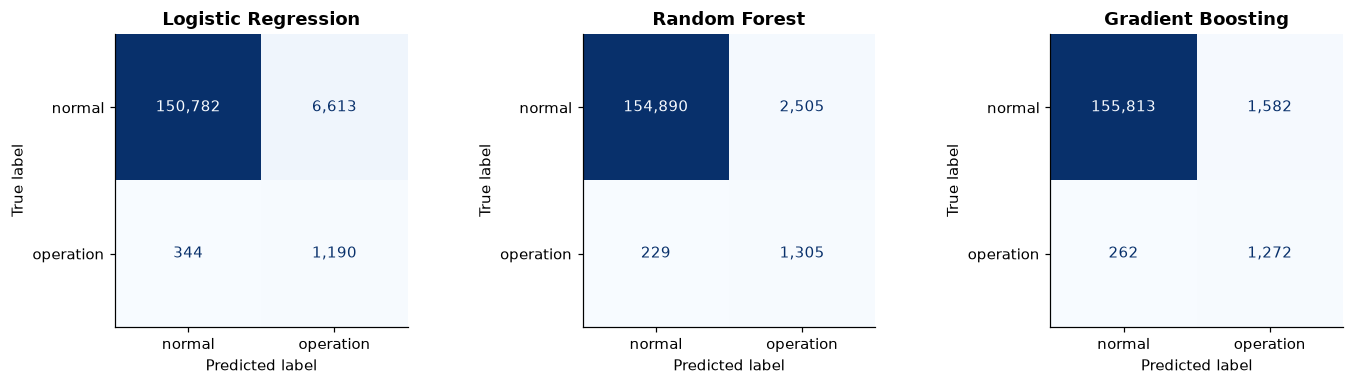

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, (m, thr)) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, (probs[name] >= thr).astype(int)),
                           display_labels=["normal", "operation"]).plot(ax=ax, colorbar=False, values_format=",", cmap="Blues")
    ax.set_title(NAMES[name]); ax.grid(False)
plt.tight_layout(); plt.show()

> **Takeaway:** Gradient Boosting finds **1,272 of 1,534** operation accounts in the test set (83 %) and wrongly flags **1,582** of 157,395 normal accounts (1 %). Logistic Regression flags 6,613 normal accounts — four times more false alarms.

## 7 · Evaluation on campaigns the model never saw
A random split mixes every campaign into training and test, so the model has already seen each operation's style.
The real use is spotting a **new** operation, so we also hold out **one whole campaign at a time**: train on the
others, test on it, repeat for all six (leave-one-campaign-out).

In [13]:
loco = {}
for name in ["logreg", "rf", "hgb"]:
    loco[name], _, _ = M.loco(df, features, name)
    loco[name]["accuracy"] = (loco[name]["tp"] + loco[name]["tn"]) / loco[name]["n_test"]
loco_table = pd.DataFrame({NAMES[n]: t[["accuracy", "precision", "recall", "f1", "pr_auc"]].mean() for n, t in loco.items()}).T
loco_table

,accuracy,precision,recall,f1,pr_auc
Logistic Regression,0.910,0.217,0.693,0.313,0.359
Random Forest,0.945,0.342,0.672,0.428,0.481
Gradient Boosting,0.948,0.351,0.671,0.433,0.535


In [14]:
best = loco["hgb"].set_index("held_out")
best[["n_test", "n_pos", "accuracy", "precision", "recall", "f1", "pr_auc", "precision_at_100"]]

,n_test,n_pos,accuracy,precision,recall,f1,pr_auc,precision_at_100
held_out,,,,,,,,
honduras_022020,6260,875,0.895,0.618,0.655,0.636,0.696,0.980
other,70738,2455,0.943,0.356,0.776,0.488,0.680,1.000
sa_eg_ae_022020,76808,735,0.984,0.319,0.601,0.417,0.489,0.960
saudi_arabia_112019,482243,1454,0.984,0.132,0.786,0.225,0.398,0.810
serbia_022020,13011,1152,0.897,0.427,0.485,0.454,0.472,0.870
turkey_052020,145585,999,0.984,0.255,0.720,0.377,0.477,0.890


> **Takeaway:**
> - On campaigns the model never saw, every score drops — this is the honest, real-world number. Gradient Boosting stays best: **F1 0.43**, precision 0.35, recall 0.67, PR-AUC 0.54.
> - Precision is lowest on Saudi Arabia (0.13), where only 0.3 % of accounts are operations — yet **81 of the model’s top 100** Saudi accounts are real operation accounts. Ranking works better than a yes/no label, so the app ranks accounts for a person to review.
> - Small differences from `docs/RESULTS.md` (e.g. 87 of the top 100 there) come from the random sample of normal accounts used in training.

### 7.1 What drives the model?

In [15]:
no_text, _, _ = M.loco(df, [c for c in features if "cosine" not in c], "hgb")
pd.DataFrame({"all features": loco["hgb"][["f1", "pr_auc"]].mean(),
              "without text similarity": no_text[["f1", "pr_auc"]].mean()}).T

,f1,pr_auc
all features,0.433,0.535
without text similarity,0.138,0.144


> **Takeaway:** without the nine text-similarity features, F1 falls from **0.43 to 0.14**. Copied wording is the model’s main signal. 80 % of normal accounts have a similarity of exactly 0, which may partly be how the dataset was built — so real-world results could be lower. We state this in the report and in the app.

## 8 · Model selection

**Chosen model: Gradient Boosting.**

| | Logistic Regression | Random Forest | **Gradient Boosting** |
|---|---|---|---|
| F1 — test set | 0.26 | 0.49 | **0.58** |
| F1 — unseen campaigns | 0.31 | 0.43 | **0.43** |
| PR-AUC — unseen campaigns | 0.36 | 0.48 | **0.54** |
| Handles missing values in uploaded files | no | no | **yes** |

- Highest F1 and PR-AUC in both tests.
- Logistic Regression is too simple: it cannot combine signals like *young* **and** *copying* **and** *in a group*.
- Random Forest is close on unseen campaigns but ranks worse and is slower and larger to deploy.
- Adding the co-reply network features raises Gradient Boosting’s PR-AUC further to **0.58** (`docs/RESULTS.md`).

## 9 · Deployment and conclusion

**Live app:** https://cluex-tool.streamlit.app — upload a campaign, a replies file or type rows in; the model scores every account, shows the groups, and gives a downloadable report.

**What we learned**
1. Operation accounts copy each other, are new, and reply in groups.
2. With 1 % operation accounts, accuracy is meaningless — F1, precision and recall tell the real story.
3. Gradient Boosting is the best model (F1 0.58 on the test set, 0.43 on unseen campaigns).
4. The model ranks well but is not precise enough to label automatically, so a person makes the final call.

**Limitations:** labels mean “suspended by Twitter”, not proven coordination; the data is Twitter 2018–2021; the model relies heavily on text similarity.